# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv') #completa el código
usage = pd.read_csv('/datasets/usage.csv') #completa el código

In [3]:
plans.head() # mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head() # mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head() # mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info() # inspección de plans 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
 users.info() # inspección de users 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
 usage.info() # inspección de usage

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum()) # Cantidad de valores nulos
print(users.isna().mean()) # Proporción de valores nulos

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum()) # Cantidad de valores nulos
print(usage.isna().mean()) # Proporción de valores nulos

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción? ¿Qué estrategia utilizar?
  
En el dataset users, las columnas con valores faltantes son: city (469, 11.7%) y churn_date (3534, 88.35%) .   En el caso de la columna city, ya que se trata de una proporción moderada, se puede rellenar los valores nulos con una etiqueta categórica como "No especificado". Respecto a la columna churn_date se pueden mantener los nulos porque su proporción es mínima y la fecha vacía de baja podría indicar que el usuario sigue activo.

En el dataset usage, las columnas con valores faltantes son date (50, 0.12%), duration (22076, 55.19%) y length (17896,44.74%). En la columna date se puede mantener las filas faltantes como nulos o imputar con la mediana ya que representa una fracción pequeña de los datos, lo que no afectará de forma negativa. La columna duración, al superar el 55% de datos faltantes se puede investigar e imputar si es importante para el estudio. De la misma forma, en la columna length ya que su porcentaje de nulos es elevado.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
columnas_numericas = ["user_id","age"]
users[columnas_numericas].describe()
# explorar columnas numéricas de users

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` representa identificadores únicos de usuarios.
- La columna `age` se observan datos atípicos con -999. También es importante la diferencia entre el promedio y la desviación estandar.

In [13]:
columnas_numericas = ["id","user_id"]
usage[columnas_numericas].describe()

# explorar columnas numéricas de usage

,id,user_id
count,40000.00000,40000.000000
mean,20000.50000,12002.405975
std,11547.14972,1157.279564
min,1.00000,10000.000000
25%,10000.75000,10996.000000
50%,20000.50000,12013.000000
75%,30000.25000,13005.000000
max,40000.00000,13999.000000


- Las columnas `id` y `user_id`presentan las estadísticas de la tabla relativas a la identificación del usuario. Id va desde 1 hasta 40000 con un total de 40000 registros, mientras que user_id oscila entre los valores de 10000 y 13999, reflejando las interacciones asociadas a dichos usuarios.   

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()


,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


- La columna city tiene 7 valores únicos, siendo "Bogotá" la categoría más frecuente (top) con 808 repeticiones en un total de 3531 registros válidos.
- La columna plan tiene 2 valores únicos, siendo "Basico" el plan más frecuente con 2595 repeticiones de un total de 4000 registros

In [15]:
# explorar columna categórica de usage
usage['type'].describe() # completa el código

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` tiene 2 valores únicos, siendo "text" el tipo más frecuente con 22092 apariciones dentro de los 40000 registros totales de uso.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?

En la columna age (dataset users), se identificó un valor mínimo de -999.0. Este número actúa claramente como un valor sentinel ya que las edades humanas no pueden tomar valores negativos. La presencia de este dato anómalo distorsiona las métricas estadísticas, provocando una considerable discrepancia entre la media y la desviación estándar de la columna.

- ¿Qué acción tomarías?
  
Identificación y filtrado: Aislar los registros donde la edad sea menor a 0 para inspeccionar cuántos casos existen.

Tratamiento de limpieza: Se podría imputar los datos con la mediana ya que, como se identificó anteriormente, aunque su cantidad no es muy significativa es importante quitar el sesgo que está causando.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] =  pd.to_datetime(users["reg_date"], errors="coerce")  # completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"], errors="coerce") # completa el código

In [18]:
users['reg_date'].describe () # Revisar los años presentes en `reg_date` de users


count                    4000
unique                   3961
top       2026-05-10 00:00:00
freq                       40
first     2022-01-01 00:00:00
last      2026-05-10 00:00:00
Name: reg_date, dtype: object

En `reg_date`, el rango abarca desde el 2022-01-01 hasta el 2026-05-10. Dado que se señala que la fecha del dataframe es solo hasta el 2024, se evidencia que existen registros con años futuros erróneos. 

In [19]:
usage['date'].describe () # Revisar los años presentes en `date` de usage


count                             39950
unique                            39950
top       2024-06-16 13:26:59.770494262
freq                                  1
first               2024-01-01 00:00:00
last                2024-06-30 00:00:00
Name: date, dtype: object

En `date`, los datos se concentran de manera consistente entre el 2024-01-01 y el 2024-06-30, por lo que no se aprecian años imposibles ni anomalías temporales graves en este bloque. Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
  
Sí, en la columna reg_date del dataset users, se registra como fecha máxima (last) el 2026-05-10. Teniendo en cuenta que el alcance del análisis está delimitado para trabajar con información hasta el año 2024, cualquier registro con fechas posteriores a diciembre de 2024 se considera un año fuera de rango o un registro con datos erróneos. 

Por el contrario, en la columna date del dataset usage, los datos se encuentran acotados correctamente entre el 2024-01-01 y el 2024-06-30, por lo que no muestran anomalías temporales.

- ¿Qué harías con ellas?

Como la cantidad con fechas fuera de rango en la columna reg_date es apenas el 1% (40), se puede limitar la fecha al año 2024 para no tener dificultades al momento de trabajar con estos datos.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users.loc[users['age'] == -999, 'age'] = age_mediana

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] =users['city'].replace("?", pd.NA)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [22]:
# Marcar fechas futuras como NA para reg_date
fecha_limite = "2024-12-31"
users.loc[users["reg_date"] > fecha_limite, "reg_date"] = pd.NaT

# Verificar cambios
users["reg_date"].describe()

count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage["duration_MAR"] = usage["duration"].isna()
usage.groupby("type")["duration_MAR"].mean()

type
call    0.000000
text    0.999276
Name: duration_MAR, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage["length_MAR"] = usage["length"].isna()
usage.groupby("type")["length_MAR"].mean()

type
call    0.99933
text    0.00000
Name: length_MAR, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

En el caso de la columna de duration, los datos nulos están determinados por el tipo de servicio, en este caso es mensajes de texto que no tienen tiempo de duración. Respecto a la columna de length, de la misma forma, los datos nulos corresponden a la duración de la llamada, datos que no se registran en text porque no corresponden. Entonces, en ambos casos se los deja como MAR.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
   cant_mensajes=("is_text", "count"),
   cant_llamadas=("is_call","count"), 
   cant_minutos_llamada=("duration", "sum")
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,10,10,23.70
1,10001,15,15,33.18
2,10002,7,7,10.74


In [26]:
# Renombrar columnas

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,10,10,23.70
1,10001,15,15,33.18
2,10002,7,7,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios

user_profile = usage_agg.merge(users, on="user_id", how="left")
user_profile.head(5)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,10,10,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,15,15,33.18,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,7,7,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,14,14,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,7,7,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
col_num_up=['cant_mensajes','cant_llamadas','cant_minutos_llamada','age']
user_profile[col_num_up].describe()



,cant_mensajes,cant_llamadas,cant_minutos_llamada,age
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,10.002501,10.002501,23.317054,48.124531
std,3.191878,3.191878,18.168095,17.692032
min,1.000000,1.000000,0.000000,18.000000
25%,8.000000,8.000000,11.120000,33.000000
50%,10.000000,10.000000,19.780000,47.000000
75%,12.000000,12.000000,31.415000,63.000000
max,27.000000,27.000000,155.690000,79.000000


In [29]:
# Distribución porcentual del tipo de plan
col_cat_up=['plan']
user_profile[col_cat_up].describe()


,plan
count,3999
unique,2
top,Basico
freq,2594


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

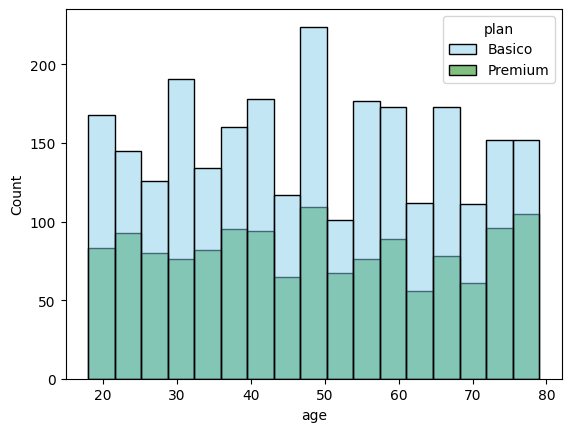

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', palette=['skyblue','green'], hue='plan')
plt.show()

💡Insights: Ambos planes (Basico y Premium) se encuentran distribuidos de manera relativamente homogénea a lo largo de los diferentes rangos de edad, lo que indica que la contratación de los planes no está restringida a un grupo etario en específico. Sin embargo, el plan Básico presenta un mayor volumen de usuarios en la mayoría de los tramos de edad en comparación con el plan Premium

- Distribución: La distribución de la variable age es simétrica ya que las frecuencias se extienden de forma regular y extendida desde los 20 hasta los 80 años, sin mostrar un sesgo marcado hacia la izquierda ni hacia la derecha. 

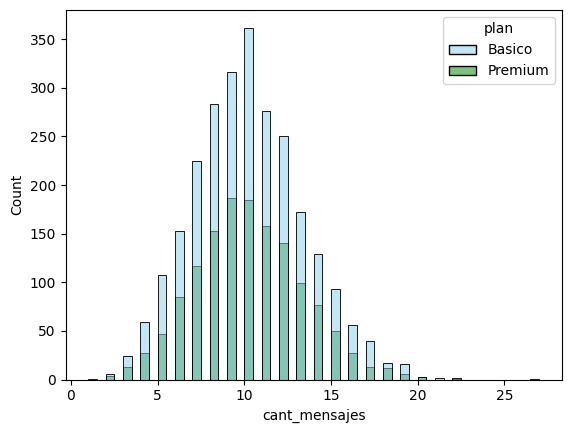

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', palette=['skyblue','green'], hue='plan')
plt.show()


💡Insights: Los usuarios con plan Básico y Premium muestran un comportamiento muy similar en cuanto a la distribución de mensajes enviados, concentrándose la mayor parte de la actividad entre los 8 y 12 mensajes. Sin embargo, el plan Básico (celeste) aporta una mayor proporción del volumen total en prácticamente todos los intervalos, especialmente alrededor del pico central de 10 mensajes.   

- Distribución: La distribución es simétrica, ya que los datos se elevan gradualmente hacia el centro (en torno a 10) y descienden de forma parecida hacia los extremos.  

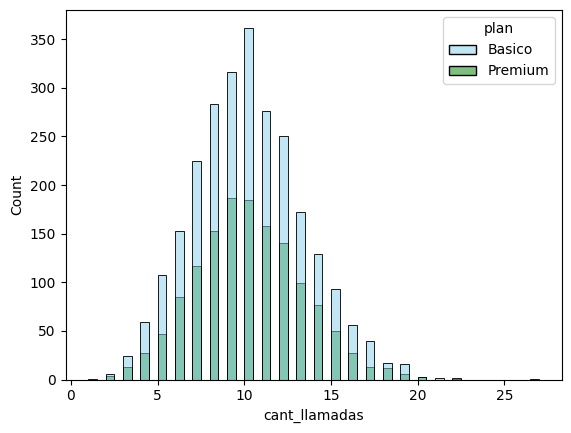

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', palette=['skyblue','green'], hue='plan')
plt.show()


💡Insights: Al igual que en el caso de los mensajes, los usuarios de ambos planes realizan un número similar de llamadas, situando el punto más alto alrededor de las 10 llamadas. No se aprecian diferencias drásticas de comportamiento por tipo de plan, aunque el plan Básico vuelve a predominar ligeramente en el volumen total de casi todas las barras.   

- Distribución: Presenta una distribución simétrica, con una campana bien definida alrededor del valor 10 y una caída simétrica hacia los valores mínimos y máximos.    

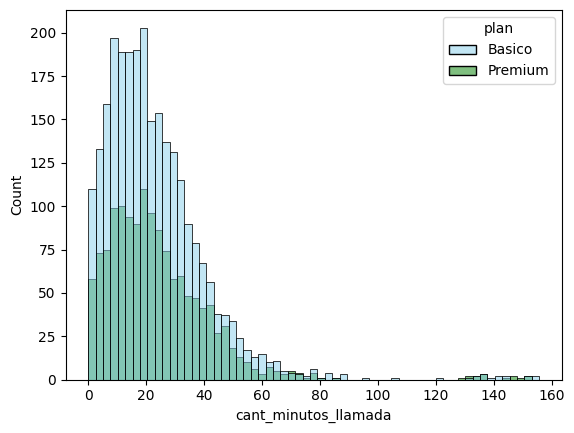

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', palette=['skyblue','green'], hue='plan')
plt.show()


💡Insights: La mayoría de los usuarios de ambos planes concentran su consumo entre los 5 y los 30 minutos de llamada. Se observa que el plan Básico aporta una proporción mayor en los picos iniciales de menor duración, mientras que en los valores más altos o extremos (hacia la derecha) la presencia de ambos planes se vuelve mínima o casi nula.   

- Distribución: La distribución está sesgada a la derecha ya que la mayor concentración de los datos se agrupa fuertemente hacia la izquierda (valores bajos de minutos) y se extiende con una larga y baja cola hacia los valores más altos.   

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

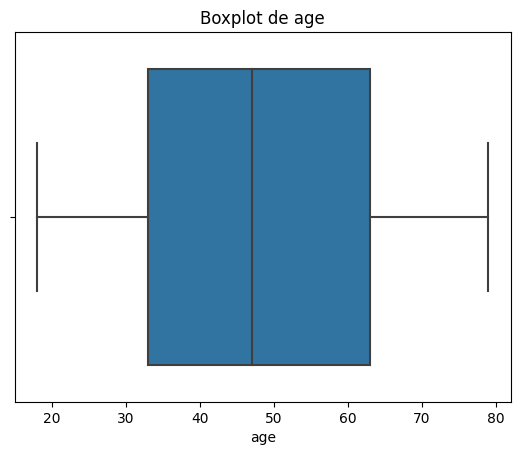

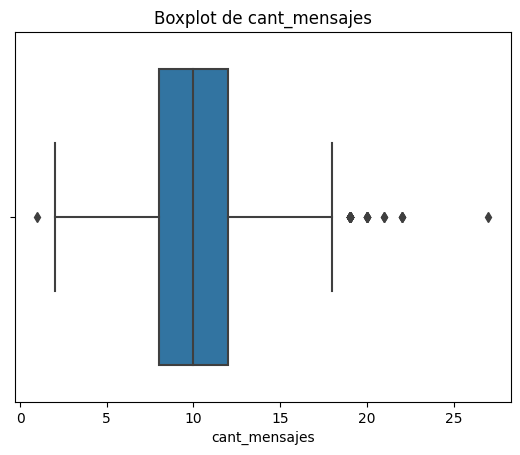

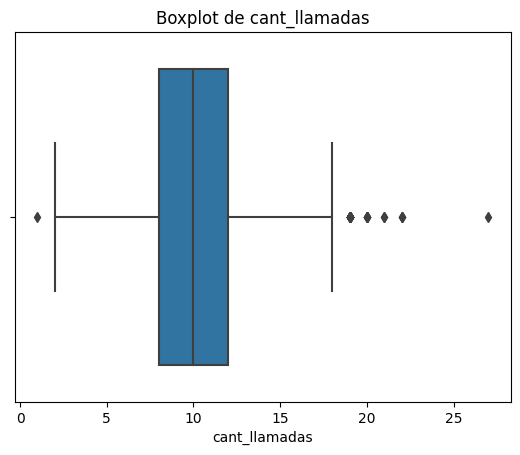

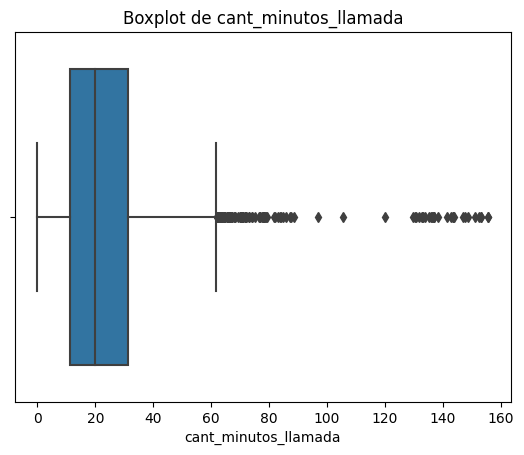

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for columna in columnas_numericas:
    sns.boxplot(data=user_profile, x=columna)
    plt.title(f'Boxplot de {columna}')
    plt.show()

💡Insights: 
- age: No presenta outliers. La distribución es simétrica y muy uniforme, con un rango intercuartílico ubicado aproximadamente entre los 33 y 63 años, y una mediana cercana a los 47 años. Todos los valores están contenidos dentro de los bigotes (aproximadamente entre 18 y 79 años).
- cant_mensajes: Presenta outliers (tanto a la izquierda como a la derecha). La mediana se ubica en 10 mensajes, y el 50% central de los usuarios envía entre 8 y 12 mensajes. Se observa un punto atípico cercano a 1 mensaje por la izquierda, y varios valores atípicos superiores a la derecha (entre 19 y 27 mensajes).
- cant_llamadas: Presenta outliers (tanto a la izquierda como a la derecha). La mediana se encuentra en 10 llamadas. Muestra un valor atípico inferior de 1 llamada a la izquierda y varios valores atípicos superiores a la derecha que van de 19 a 27 llamadas.
- cant_minutos_llamada: Presenta una gran cantidad de outliers por la derecha. La mediana se sitúa alrededor de los 20 minutos y el 50% central consumido está entre los 11 y 31 minutos. A partir de los 62 minutos aproximadamente, se observa una alta densidad de puntos atípicos que se extienden hasta alcanzar más de 150 minutos de llamada.   

In [35]:
# Calcular límites con el método IQR

columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for user_profile_iqr in columnas_limites:
    Q1 = user_profile[ user_profile_iqr ].quantile(0.25)
    Q3 = user_profile[ user_profile_iqr ].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    print(f'Límite superior de { user_profile_iqr }: {limite_superior}')




Límite superior de cant_mensajes: 18.0
Límite superior de cant_llamadas: 18.0
Límite superior de cant_minutos_llamada: 61.8575


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,10.002501,10.002501,23.317054
std,3.191878,3.191878,18.168095
min,1.000000,1.000000,0.000000
25%,8.000000,8.000000,11.120000
50%,10.000000,10.000000,19.780000
75%,12.000000,12.000000,31.415000
max,27.000000,27.000000,155.690000


💡Insights: 
* cant_mensajes: Mantener los outliers porque los valores máximos observados (hasta 27 mensajes) se encuentran dentro de un rango completamente lógico y realista para la actividad de un usuario activo. No representan errores de registro ni centinels imposibles.
* cant_llamadas: Mantener los outliers. De manera similar a los mensajes, un máximo de 27 llamadas refleja una conducta de uso válida y esperada dentro de la base de usuarios. Descartar estos valores altos eliminaría información genuina sobre los clientes que más interactúan con el servicio.
* cant_minutos_llamada. Mantener los outliers. Aunque el valor máximo llega a 155.69 minutos (muy por encima de la media de 23.31 minutos), este comportamiento es completamente verosímil en llamadas de larga duración. Su eliminación sesgaría el análisis del consumo real de llamadas y haría perder visibilidad sobre los usuarios de mayor valor o intensidad de uso.   

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
user_profile['uso_total'] = user_profile['cant_mensajes'] + user_profile['cant_llamadas'] 

def grupo_uso (uso_total):

    if uso_total < 5: 
       return "Bajo uso"
    elif uso_total < 10:
       return "Uso medio"
    else:
        return "Alto uso"

user_profile['grupo_uso']= user_profile['uso_total'].apply(grupo_uso) 

In [38]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,uso_total,grupo_uso
0,10000,10,10,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,20,Alto uso
1,10001,15,15,33.18,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,30,Alto uso
2,10002,7,7,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,14,Alto uso
3,10003,14,14,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,28,Alto uso
4,10004,7,7,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,14,Alto uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
user_profile['edad_total'] = user_profile['age'] 

def grupo_edad (edad_total):

    if edad_total < 30: 
       return "Joven"
    elif edad_total < 60:
       return "Adulto"
    else:
        return "Adulto Mayor"

user_profile['grupo_edad']= user_profile['edad_total'].apply(grupo_edad) 


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

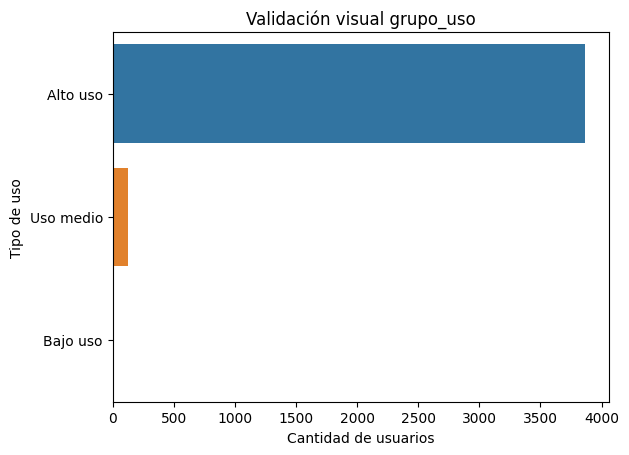

In [40]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, y='grupo_uso', order=user_profile['grupo_uso'].value_counts().index)
plt.title('Validación visual grupo_uso')
plt.xlabel("Cantidad de usuarios")
plt.ylabel("Tipo de uso")
plt.show()


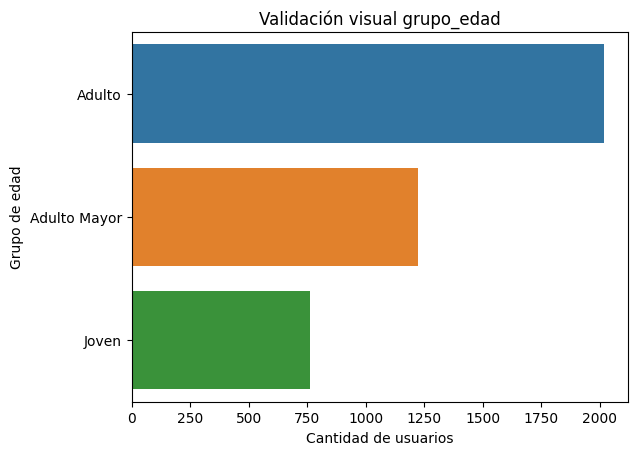

In [41]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, y='grupo_edad', order=user_profile['grupo_edad'].value_counts().index)
plt.title('Validación visual grupo_edad')
plt.xlabel("Cantidad de usuarios")
plt.ylabel("Grupo de edad")
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

Valores sentinel e inválidos: Se detectaron valores -999 en la columna age de la tabla users. Esto afectaba inicialmente los cálculos de media y desviación estándar de la edad.   También se identificaron anomalías temporales en la columna reg_date que contenía fechas futuras que llegaban hasta mayo de 2026, por lo que se procedió a limitar su alcance temporal al cierre del año 2024.

🔍 **Segmentos por Edad**

Composición demográfica: La base de clientes se compone de tres grupos principales: 
* Adultos (~2,000 usuarios, siendo la categoría predominante)
* Adultos Mayores (~1,220 usuarios) y,
*  Jóvenes (~760 usuarios).   

Distribución de planes: La distribución de edades en los planes Básico y Premium es bastante homogénea (simétrica entre los 18 y 79 años), lo que evidencia que la contratación de un plan superior no depende estrictamente de la edad del usuario.   

📊 **Segmentos por Nivel de Uso**

Comportamiento dominante: Más del 95% de los usuarios se concentran en la categoría de Alto uso (superando el umbral de 10 llamadas o 10 mensajes).   

Proporciones menores: La categoría Uso medio representa un grupo reducido (~120 usuarios), mientras que Bajo uso es prácticamente marginal (cercano al 0%).  

➡️ Esto sugiere que los umbrales definidos para clasificar el uso (5 y 10 llamadas o mensajes) resultaron ser demasiado bajos para la dinámica real de los clientes de ConnectaTel. 

🔍 Segmentos más valiosos: Los usuarios con el plan Premium que además presentan consumo de cantidad de minutos en llamadas extendido (picos de 60 a más de 150 minutos) constituyen el segmento de mayor valor operativo para ConnectaTel.   

- Implicación de los outliers: Los valores atípicos detectados en cant_minutos_llamada (hasta 155.69 minutos) no son errores de medición, sino hábitos reales de estos usuarios. Conservar estos outliers fue clave para identificar la demanda real sobre la infraestructura de red sin subestimar el consumo máximo por usuario.

💡 **Recomendaciones**

- Reajuste de criterios de segmentación: Redefinir las reglas de negocio para grupo_uso, elevando los umbrales (por ejemplo, tomar la mediana o percentiles 75 para marcar "Alto uso") de modo que se refleje una verdadera diferenciación entre clientes esporádicos e intensivos.
  
- Rediseño de la oferta comercial (Planes): Dado que el plan Básico abarca a la mayoría de los usuarios de alto tráfico de llamadas y mensajes, se recomienda empaquetar ofertas con más gigas/datos o incentivos exclusivos en el plan Premium para impulsar la migración de este gran volumen de usuarios intensivos hacia planes de mayor margen.

- Adicionalmente, se sugiere aprovechar la integración y limpieza de los datos para realizar análisis cruzados más profundos —como relacionar el tipo de plan con el grupo de edad de manera conjunta—, así como incorporar segmentaciones geográficas por país (México y Colombia) y evaluar la antigüedad del cliente a partir de su fecha de registro (reg_date). Esto permitirá descubrir microsegmentos de alto valor y afinar con mayor precisión las estrategias de retención y personalización de la oferta comercial para ConnectaTel.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

README

Análisis de Uso de Servicios Móviles en ConnectaTel (LATAM)

🎯 1. Objetivo del Proyecto

* Analizar cómo los clientes utilizan realmente los servicios de telefonía móvil (llamadas y mensajes), identificar patrones de uso y comportamientos atípicos (como posibles sesgos, fraude o errores de registro); y comprender qué segmentos de clientes muestran necesidades diferenciadas, con el propósito de optimizar la oferta comercial y mejorar la experiencia del usuario.

💡 Preguntas de Negocio:

* ¿Qué segmentos de clientes muestran mayor o menor uso de llamadas y mensajes?
* ¿Qué usuarios presentan valores atípicos que puedan indicar comportamientos inusuales, fraude o errores de registro?
* ¿Cómo varía el uso según la edad y el tipo de plan contratado?
* ¿Qué patrones pueden ayudar a diseñar mejores planes, optimizar la oferta y mejorar la satisfacción del cliente?

📂 2. Datasets Utilizados

El análisis integra las siguientes fuentes de información clave:

* plans.csv: Detalles del catálogo de planes actuales (precio mensual, minutos incluidos, GB incluidos y costos adicionales).

* users_latam.csv: Información demográfica y de perfil del cliente en México y Colombia (ID de usuario, edad, ciudad, fecha de registro, fecha de baja y plan contratado).

* usage.csv: Registro transaccional del uso real de servicios (llamadas realizada/duración en minutos y mensajes enviados).

Restricción Temporal: El alcance de las métricas y eventos analizados se encuentra acotado al año 2024.

🔄 3. Etapas del Análisis

- Exploración y Diagnóstico Inicial: Inspección de columnas numéricas y categóricas clave.

- Identificación de valores sentinels (age = -999) y registros temporales fuera de rango (fechas de registro en 2026).

- Limpieza y Preparación de Datos:

* Conversión de tipos de datos a datetime y numéricos estándar.
* Reemplazo o filtrado de valores inválidos/centinela.
* Aplicación del filtro temporal estricto para registros hasta el año 2024.
* Análisis Exploratorio de Datos y Visualización:
  - Análisis de distribuciones (histogramas) por plan (Básico vs. Premium) y edad.
  - Detección e interpretación de outliers mediante boxplots (confirmando que consumos altos de minutos/llamadas responden a usos legítimos).

- Ingeniería de Características y Segmentación:

* Creación de clasificaciones de consumo (grupo_uso: Bajo, Medio, Alto) y grupos etarios (Joven, Adulto, Alto Mayor).

- Insights Ejecutivos y Recomendaciones:

* Formulación de conclusiones accionables sobre el ajuste de umbrales de uso y la reestructuración de la oferta comercial de ConnectaTel.

🚀 4. Guía de Reproducción del Notebook

Puedes ejecutar el cuaderno directamente en Google Colab:
* Abre Google Colab.
* Carga el archivo del notebook .ipynb.
* Sube las fuentes de datos (plans.csv, users_latam.csv, usage.csv) en el panel de archivos de Colab.
* Ejecuta las celdas de forma secuencial.